In [1]:
# -*- coding: utf-8 -*-
"""
Created on November 10, 2026
Revised on November 12, 2026

@author:       Oscar Trevizo
@institution:  Harvard Extension School — Graduate Data Science Program (2023)
@context:      Independent project — applying course concepts to real-world data
@environment:  Python 3.14.6 | myenv | MacBook Air M5

Logistic Regression Decision Boundary Vignette — Iris Dataset
==============================================================

Description:
    Shows the line a logistic regression draws between two classes, and
    that this line comes straight from the model's intercept_ and coef_.

    With two predictors, the decision boundary is where P = 0.5, i.e.
    where the log-odds are 0:
        beta0 + beta1*x1 + beta2*x2 = 0   →   x2 = m*x1 + b
    a classic line with slope m = -beta1/beta2 and intercept b = -beta0/beta2.

    Covers:
      - The Iris dataset, petal length and petal width
      - Part 1: setosa vs. the rest, a perfectly separable (easy) case, 
        and why perfect separation needs regularization
      - Part 2: versicolor vs. virginica, an overlapping case
      - Computing the boundary line from intercept_ and coef_
      - Stratified train / test split (80 / 20) in both parts
      - Flowers on the wrong side of the line (misclassified)
      - DecisionBoundaryDisplay probability shading, with the computed
        line sitting exactly on its 0.5 edge
      - Other thresholds give parallel lines

    Each part splits the flowers 80/20 into training and test sets: the
    line is learned from the training flowers and checked on the test
    flowers.

    Companion to logistic_regression_vignette.ipynb (ISLP Default data), 
    which covers thresholds, the accuracy trap and confounding.

    Colors follow the Harvard palette used in earlier notebooks.

Data:
    Iris — 150 flowers, 50 each of setosa, versicolor and virginica.
    Collected by Edgar Anderson; made famous by R. A. Fisher (1936).
    Loaded with seaborn.load_dataset('iris'), which downloads it from the
    seaborn-data repository on GitHub (same values as sklearn's load_iris).

References:
    1. Fisher, R. A. (1936). The use of multiple measurements in taxonomic
       problems. Annals of Eugenics, 7(2), 179–188.
    2. seaborn load_dataset documentation
       https://seaborn.pydata.org/generated/seaborn.load_dataset.html
    3. SciKit-Learn DecisionBoundaryDisplay documentation
       https://scikit-learn.org/stable/modules/generated/sklearn.inspection.DecisionBoundaryDisplay.html
    4. James, G., Witten, D., Hastie, T., Tibshirani, R., and Taylor, J. (2017).
       An Introduction to Statistical Learning with Applications in R.
       Springer. Chapter 4: Classification. https://www.statlearning.com
    5. James, G., Witten, D., Hastie, T., Tibshirani, R., and Taylor, J. (2023).
       An Introduction to Statistical Learning with Applications in Python.
       Springer. Chapter 4: Classification. https://www.statlearning.com

Revision History:
    2026-11-10  Original development
                - Setosa vs. rest (separable) and versicolor vs. virginica
                - Boundary line computed from intercept_ and coef_
                - DecisionBoundaryDisplay overlay; threshold lines

    2026-11-12  Teaching revisions
                - Data loaded with seaborn.load_dataset('iris'), a plain
                  DataFrame, replacing load_iris() and its Bunch
                - iris_df.info() shows the structure before anything else
                - Stratified 80/20 train / test split in Parts 1 and 2;
                  models fit on training flowers, scored on both sets
                - Wrong-side plot shows the test flowers; the jitter
                  plot shows the training flowers
                - Boundary note cites ISLR 4.3 (pp. 130-132): what
                  is modeled, p(X) = Pr(Y = 1 | X), and the log-odds
                  (logit); both terms used
                - Check cell: P(virginica) = 0.5 on the line, below and
                  above it at three petal lengths
                - Boundary written as y = mx + b (slope m, intercept b);
                  boundary_width() and the Part 2 print compute m and b;
                  note on the line's b vs. scikit-learn's intercept_
                - Logit coefficients named beta0, beta1, beta2
"""

"\nCreated on November 10, 2026\nRevised on November 12, 2026\n\n@author:       Oscar Trevizo\n@institution:  Harvard Extension School — Graduate Data Science Program (2023)\n@context:      Independent project — applying course concepts to real-world data\n@environment:  Python 3.14.6 | myenv | MacBook Air M5\n\nLogistic Regression Decision Boundary Vignette — Iris Dataset\n==============================================================\n\nDescription:\n    Shows the line a logistic regression draws between two classes, and\n    that this line comes straight from the model's intercept_ and coef_.\n\n    With two predictors, the decision boundary is where P = 0.5, i.e.\n    where the log-odds are 0:\n        beta0 + beta1*x1 + beta2*x2 = 0   →   x2 = m*x1 + b\n    a classic line with slope m = -beta1/beta2 and intercept b = -beta0/beta2.\n\n    Covers:\n      - The Iris dataset, petal length and petal width\n      - Part 1: setosa vs. the rest, a perfectly separable (easy) case, \n      

# The Line That Splits the Data

A logistic regression with two predictors draws a **straight line** through
the scatter plot: flowers on one side get one answer, flowers on the other side
get the other.

That line is not something extra the model learns. It comes straight from the
same `intercept_` and `coef_` we have read in every regression so far.

# Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import confusion_matrix

## Harvard palette

In [3]:
CRIMSON   = '#A51C30'
ROYALBLUE = '#002366'
INDIGO    = '#293352'
IVY       = '#52854C'
SAFFRON   = '#D16103'
SHADE     = '#BAC5C6'
SLATE     = '#8996A0'

SPECIES_PALETTE = {'setosa': IVY, 'versicolor': ROYALBLUE, 'virginica': CRIMSON}

sns.set_style('darkgrid')

# Load the data

seaborn ships a few classic datasets. `sns.load_dataset('iris')` downloads
Iris and returns it as a pandas DataFrame, with short column names and the
species already spelled out.

In [4]:
iris_df = sns.load_dataset('iris')

## Structure of the data

Before anything else, look at what we got: 150 rows, four measurements in
centimeters (sepal and petal, length and width), and the species.

In [5]:
iris_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


## First rows

This vignette uses the two **petal** measurements: `petal_length` and
`petal_width`.

In [6]:
iris_df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [7]:
iris_df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

# Explore: petal length vs. petal width

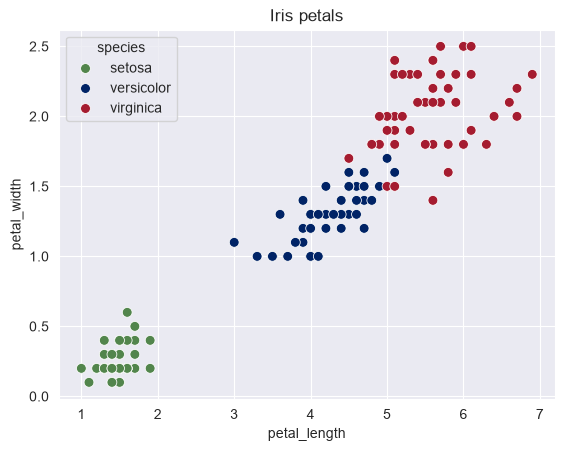

In [8]:
sns.scatterplot(
    data=iris_df, 
    x='petal_length', 
    y='petal_width', 
    hue='species', 
    palette=SPECIES_PALETTE, 
    s=50, 
)
plt.title('Iris petals')
plt.show()

- **Setosa** sits on its own in the corner: small petals, far from the others.
- **Versicolor** and **virginica** touch, and overlap a little.

Two very different classification problems in one picture.

# A helper: the boundary line from the coefficients

## What we are modeling

ISLR Section 4.3 (p. 130): logistic regression models "the probability that Y
belongs to a particular category." On p. 131 the book writes this probability
as

$$p(X) = \Pr(Y = 1 \mid X)$$

using the generic 0/1 coding for the response. In Part 2, Y = 1 means
virginica and Y = 0 means versicolor (the second class in `classes_` is the 1).

## The log-odds, or logit

The book (p. 132) shows that the model is a straight line on the
**log-odds** scale, also called the **logit**:

$$\log\left(\frac{p(X)}{1 - p(X)}\right) = \beta_0 + \beta_1 X_1 + \beta_2 X_2$$

We take that result as given. It is what scikit-learn fits: `intercept_` holds
$\beta_0$ and `coef_` holds $\beta_1$ and $\beta_2$, with $X_1$ = petal length
and $X_2$ = petal width.

## Where the line goes

The boundary is where P = 0.5, the 50/50 case where the model cannot tell the
two classes apart. There the odds are 0.5 / 0.5 = 1, and log(1) = 0, so the
**logit is 0**:

$$\beta_0 + \beta_1 \cdot \text{length} + \beta_2 \cdot \text{width} = 0$$

Solve for width:

$$\text{width} = \left(-\frac{\beta_1}{\beta_2}\right) \cdot \text{length} + \left(-\frac{\beta_0}{\beta_2}\right)$$

## The classic line: y = mx + b

That is an ordinary straight line, $y = mx + b$, with

| Line | Here | From scikit-learn |
|---|---|---|
| $y$ | petal width | |
| $x$ | petal length | |
| $m$, the slope | $-\beta_1 / \beta_2$ | from `coef_` |
| $b$, the intercept | $-\beta_0 / \beta_2$ | from `intercept_` and `coef_` |

**Two different intercepts.** scikit-learn's `intercept_` ($\beta_0$) is the
intercept of the **logit** equation. The line's $b$ is where the **boundary
line** crosses the width axis (at length 0). They are different numbers: in
Part 2, $\beta_0$ is about −81 while $b$ is about 5.16.

**Other thresholds.** For a threshold $t$ other than 0.5, the logit equals
$\ln\frac{t}{1-t}$ instead of 0 (about −1.39 for $t$ = 0.2). That changes only
$b$, to $\left(\ln\frac{t}{1-t} - \beta_0\right) / \beta_2$. The slope $m$
stays the same, so the line shifts without turning: parallel lines.

`boundary_width()` below computes $m$ and $b$, then returns $m \cdot x + b$
for every petal length $x$ we give it.

In [9]:
def boundary_width(petal_length, fitted_lgr, threshold=0.5):
    """
    Petal width on the decision boundary of a two-predictor logistic regression.

    Sets the log-odds (logit) equal to the logit of the threshold t,
        beta0 + beta1*length + beta2*width = log(t / (1 - t)), 
    and solves for width. With the default threshold of 0.5 the
    right-hand side is log(1) = 0: the 50/50 line.

    The result is a classic line, y = m*x + b:
        y = petal width, x = petal length
        m = -beta1 / beta2                        (slope)
        b = (log(t / (1 - t)) - beta0) / beta2    (the line's intercept;
                                                   -beta0 / beta2 at t = 0.5)

    Parameters
    ----------
    petal_length : float or array — petal lengths (x) at which to compute the line
    fitted_lgr   : fitted LogisticRegression with predictors
                   [petal_length, petal_width], in that order
    threshold    : probability cut-off (default 0.5)

    Returns
    -------
    float or array — petal width (y) on the boundary
    """
    # The logit's coefficients, as fitted by scikit-learn
    beta0 = fitted_lgr.intercept_[0]
    beta1, beta2 = fitted_lgr.coef_[0]

    # Logit (log-odds) of the threshold: 0 when threshold = 0.5
    threshold_logit = np.log(threshold / (1 - threshold))

    # The boundary as a classic line, y = m*x + b
    slope_m = -beta1 / beta2                            # slope
    intercept_b = (threshold_logit - beta0) / beta2     # the LINE's intercept, not intercept_

    return slope_m * petal_length + intercept_b

# Part 1: setosa vs. the rest (the easy case)

Label each flower "setosa" or "other".

In [10]:
X = iris_df[['petal_length', 'petal_width']]
y_setosa = np.where(iris_df['species'] == 'setosa', 'setosa', 'other')

pd.Series(y_setosa).value_counts()

other     100
setosa     50
Name: count, dtype: int64

## Train / test split

As in every supervised model: hold out 20% of the flowers to test the model
on flowers it has not seen.

`stratify=y_setosa` keeps the same share of setosa (one in three) in both
sets, so the test set is not left with too few or too many by chance.

In [11]:
x_train, x_test, y_setosa_train, y_setosa_test = train_test_split(
    X, 
    y_setosa, 
    test_size=0.2,          # 20% of the flowers go to the test set
    stratify=y_setosa,      # same share of setosa in both sets
    random_state=40,        # same shuffle every run
)

x_train.shape, x_test.shape

((120, 2), (30, 2))

Here we keep scikit-learn's default regularization (`C=1.0`). The two groups
are **perfectly separable**: a line can split them with no mistakes. Without
regularization, the fit keeps sharpening the S-curve toward a cliff, pushing
the coefficients toward infinity. Regularization keeps them finite.

In [12]:
setosa_lgr = LogisticRegression()
setosa_lgr.fit(x_train, y_setosa_train)

setosa_lgr.intercept_, setosa_lgr.coef_

(array([7.44745776]), array([[-2.45345337, -1.01748884]]))

In [13]:
# Column order of predict_proba: "other", then "setosa"
setosa_lgr.classes_

array(['other', 'setosa'], dtype='<U6')

In [14]:
# Accuracy on the training flowers, then on the test flowers
setosa_lgr.score(x_train, y_setosa_train), setosa_lgr.score(x_test, y_setosa_test)

(1.0, 1.0)

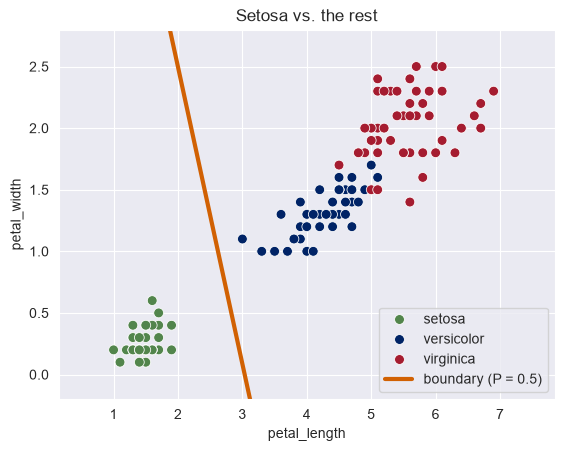

In [15]:
length_grid = np.linspace(0.5, 7.5, 200)

# All 150 flowers, and the line learned from the 120 training flowers

sns.scatterplot(
    data=iris_df, 
    x='petal_length', 
    y='petal_width', 
    hue='species', 
    palette=SPECIES_PALETTE, 
    s=50, 
)
plt.plot(
    length_grid, 
    boundary_width(length_grid, setosa_lgr), 
    color=SAFFRON, 
    linewidth=3, 
    label='boundary (P = 0.5)', 
)
plt.ylim(-0.2, 2.8)
plt.legend()
plt.title('Setosa vs. the rest')
plt.show()

Every flower on the correct side, training and test alike: accuracy 1.0 on
both. The line was learned from the 120 training flowers; the plot shows all
150.

But look at the gap between setosa and the rest. Any line through that gap
would also score 1.0. With perfectly separable data the data alone cannot pick
one line; here the regularization settles it. That is the easy case, and a
reason it teaches little about how logistic regression chooses.

# Part 2: versicolor vs. virginica (where the line has to choose)

Drop setosa and keep the two species that overlap.

In [16]:
two_species_df = iris_df[iris_df['species'] != 'setosa']

X_two = two_species_df[['petal_length', 'petal_width']]
y_two = two_species_df['species']

y_two.value_counts()

species
versicolor    50
virginica     50
Name: count, dtype: int64

## Train / test split

The same split as in Part 1: 80 flowers to learn from, 20 to check, with
10 of each species in the test set.

In [17]:
x_two_train, x_two_test, y_two_train, y_two_test = train_test_split(
    X_two, 
    y_two, 
    test_size=0.2, 
    stratify=y_two, 
    random_state=40, 
)

x_two_train.shape, x_two_test.shape

((80, 2), (20, 2))

These classes overlap, so no line is perfect and the unregularized fit is well
behaved. `C=np.inf` turns regularization off, as in the Default vignette.

In [18]:
petal_lgr = LogisticRegression(C=np.inf)
petal_lgr.fit(x_two_train, y_two_train)

petal_lgr.intercept_, petal_lgr.coef_

(array([-80.98512383]), array([[11.14898891, 15.70427876]]))

In [19]:
# Column order of predict_proba: "versicolor", then "virginica"
petal_lgr.classes_

array(['versicolor', 'virginica'], dtype=object)

## The line, from the coefficients

Compute the line's slope $m$ and intercept $b$ from scikit-learn's
`intercept_` and `coef_`, then write the boundary as $y = mx + b$.

In [20]:
beta0 = petal_lgr.intercept_[0]
beta1, beta2 = petal_lgr.coef_[0]

slope_m = -beta1 / beta2         # slope of the boundary line
intercept_b = -beta0 / beta2     # intercept of the boundary line (not intercept_)

print(f'scikit-learn:  intercept_ (beta0) = {beta0:.2f},  coef_ (beta1, beta2) = {beta1:.2f}, {beta2:.2f}')
print(f'Boundary line: m = {slope_m:.2f},  b = {intercept_b:.2f}')
print(f'               petal_width = {slope_m:.2f} * petal_length + {intercept_b:.2f}')

scikit-learn:  intercept_ (beta0) = -80.99,  coef_ (beta1, beta2) = 11.15, 15.70
Boundary line: m = -0.71,  b = 5.16
               petal_width = -0.71 * petal_length + 5.16


## Check: the line is where P = 0.5

Pick three petal lengths, and let `boundary_width()` compute the width on the
line for each. Then ask the model for P(virginica) at those points, and at
points 0.2 cm below and above the line.

In [21]:
check_lengths = np.array([4.0, 5.0, 6.0])
check_widths = boundary_width(check_lengths, petal_lgr)     # widths ON the line

def p_virginica(petal_widths):
    """P(virginica) at check_lengths and the given petal widths."""
    points_df = pd.DataFrame({'petal_length': check_lengths, 'petal_width': petal_widths})
    return petal_lgr.predict_proba(points_df)[:, 1]          # column 1 = virginica

pd.DataFrame(
    {
        'petal_length': check_lengths, 
        'boundary width': check_widths.round(3), 
        'P on the line': p_virginica(check_widths).round(3), 
        'P 0.2 cm below': p_virginica(check_widths - 0.2).round(3), 
        'P 0.2 cm above': p_virginica(check_widths + 0.2).round(3), 
    }
)

,petal_length,boundary width,P on the line,P 0.2 cm below,P 0.2 cm above
0,4.0,2.317,0.5,0.041,0.959
1,5.0,1.607,0.5,0.041,0.959
2,6.0,0.897,0.5,0.041,0.959


- **On the line**, P = 0.5 at every length: the model cannot decide.
- **Above the line** (wider petals for that length), P is above 0.5: virginica.
- **Below the line**, P is below 0.5: versicolor.

The line slopes down because both coefficients are positive: both a longer
and a wider petal push toward virginica, so a longer petal needs a narrower
width to stay on the line.

## Which test flowers land on the wrong side?

Now the real check: the 20 test flowers the model has not seen.

In [22]:
y_two_predict = petal_lgr.predict(x_two_test)
wrong_side = y_two_predict != y_two_test

# Rows: actual species, columns: predicted species (test flowers only)
confusion_matrix(y_two_test, y_two_predict, labels=['versicolor', 'virginica'])

array([[9, 1],
       [2, 8]])

In [23]:
# Accuracy on the training flowers, then on the test flowers
petal_lgr.score(x_two_train, y_two_train), petal_lgr.score(x_two_test, y_two_test)

(0.9625, 0.85)

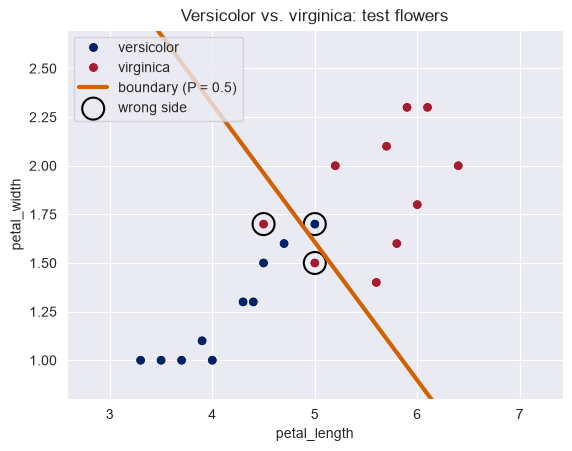

In [24]:
length_grid = np.linspace(2.8, 7.2, 200)

# The 20 TEST flowers and the line learned from the 80 training flowers
sns.scatterplot(
    x=x_two_test['petal_length'], 
    y=x_two_test['petal_width'], 
    hue=y_two_test, 
    palette=SPECIES_PALETTE, 
    s=50, 
)
plt.plot(
    length_grid, 
    boundary_width(length_grid, petal_lgr), 
    color=SAFFRON, 
    linewidth=3, 
    label='boundary (P = 0.5)', 
)
# Circle the test flowers the line puts on the wrong side
plt.scatter(
    x_two_test.loc[wrong_side, 'petal_length'], 
    x_two_test.loc[wrong_side, 'petal_width'], 
    s=250, 
    facecolors='none', 
    edgecolors='black', 
    linewidths=1.5, 
    label='wrong side', 
)
plt.ylim(0.8, 2.7)
plt.legend(loc='upper left')
plt.title('Versicolor vs. virginica: test flowers')
plt.show()

17 of 20 test flowers on the correct side: accuracy 0.85. One versicolor and
two virginica are circled, all close to the line, where the two species
overlap.

On the training flowers the score is higher (0.9625, 77 of 80). That is
normal: the line was chosen to fit those flowers. The **test** score is the
honest one, because the model never saw those flowers.

## Jitter: seeing the hidden flowers

The line also misses 3 of the 80 **training** flowers, and one of those
mistakes cannot be avoided. Iris measurements are rounded to 0.1 cm, so
several flowers share a point (16 of the 80 training flowers repeat another
flower's measurements). Identical flowers are drawn on top of each other, so
the plot shows fewer dots than there are flowers.

**Jitter** nudges each dot by a tiny random amount, in the *plot only*, the
way R's `jitter()` or ggplot's `geom_jitter()` do. The model was fit on the
real measurements; nothing about it changes.

The nudge stays under half the 0.1 cm measurement step (±0.04), so no dot
moves into a neighbor's spot.

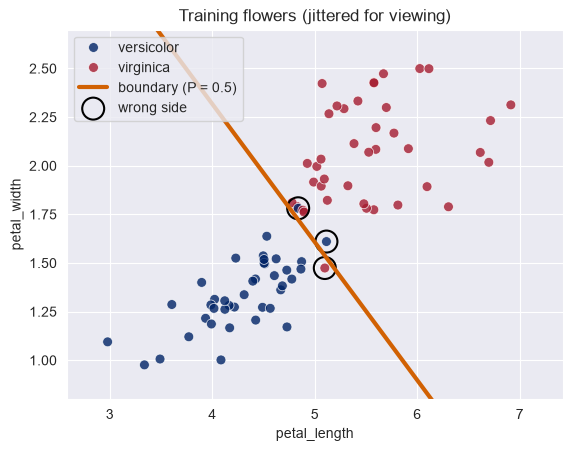

In [25]:
# Jitter for viewing only: a jittered copy of the TRAINING flowers, never used for fitting
jitter_rng = np.random.default_rng(seed=42)
jitter_size = 0.04

jittered_df = two_species_df.loc[x_two_train.index].copy()
jittered_df['petal_length'] += jitter_rng.uniform(-jitter_size, jitter_size, len(jittered_df))
jittered_df['petal_width']  += jitter_rng.uniform(-jitter_size, jitter_size, len(jittered_df))

# Training flowers on the wrong side of the line
train_wrong_side = petal_lgr.predict(x_two_train) != y_two_train

sns.scatterplot(
    data=jittered_df, 
    x='petal_length', 
    y='petal_width', 
    hue='species', 
    palette=SPECIES_PALETTE, 
    alpha=0.8, 
    s=50, 
)
plt.plot(
    length_grid, 
    boundary_width(length_grid, petal_lgr), 
    color=SAFFRON, 
    linewidth=3, 
    label='boundary (P = 0.5)', 
)
# Circle the wrong-side training flowers at their jittered positions
plt.scatter(
    jittered_df.loc[train_wrong_side, 'petal_length'], 
    jittered_df.loc[train_wrong_side, 'petal_width'], 
    s=250, 
    facecolors='none', 
    edgecolors='black', 
    linewidths=1.5, 
    label='wrong side', 
)
plt.ylim(0.8, 2.7)
plt.legend(loc='upper left')
plt.title('Training flowers (jittered for viewing)')
plt.show()

Near (4.8, 1.8) the three flowers now separate: the circled versicolor and the
two virginica that share its measurements.

## The probability behind the line

`DecisionBoundaryDisplay` asks the fitted model for P(virginica) at every
point of a fine grid and shades it: blue where versicolor is likely, crimson
where virginica is likely.

On top, the line computed from `intercept_` and `coef_`. It sits exactly where
the shading changes color, at P = 0.5: same model, two ways to draw it.

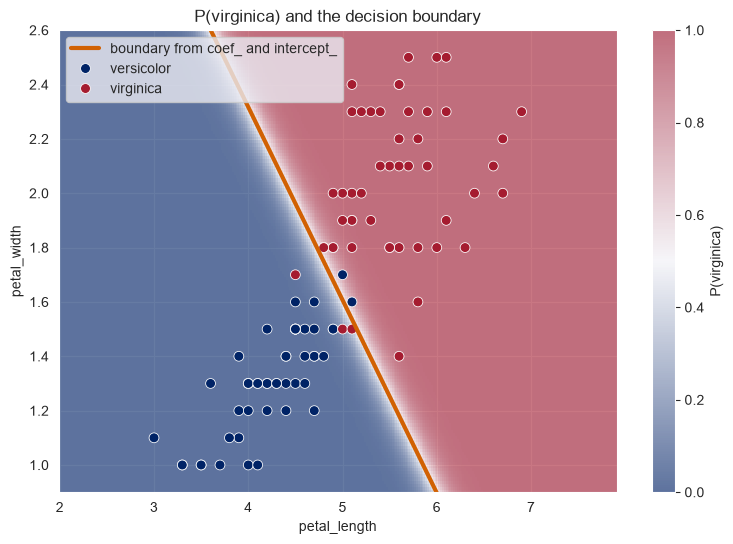

In [26]:
# Harvard colors from ROYALBLUE (P near 0) through white to CRIMSON (P near 1)
harvard_cmap = LinearSegmentedColormap.from_list(
    'harvard', 
    [ROYALBLUE, 'white', CRIMSON], 
)

fig, ax = plt.subplots(figsize=(9, 6))

boundary_display = DecisionBoundaryDisplay.from_estimator(
    petal_lgr, 
    X_two, 
    response_method='predict_proba', 
    plot_method='pcolormesh', 
    cmap=harvard_cmap, 
    vmin=0, 
    vmax=1, 
    alpha=0.6, 
    grid_resolution=300, 
    ax=ax, 
)
fig.colorbar(boundary_display.surface_, ax=ax, label='P(virginica)')

ax.plot(
    length_grid, 
    boundary_width(length_grid, petal_lgr), 
    color=SAFFRON, 
    linewidth=3, 
    label='boundary from coef_ and intercept_', 
)
sns.scatterplot(
    data=two_species_df, 
    x='petal_length', 
    y='petal_width', 
    hue='species', 
    palette=SPECIES_PALETTE, 
    edgecolor='white', 
    s=50, 
    ax=ax, 
)
ax.set_ylim(X_two['petal_width'].min() - 0.1, X_two['petal_width'].max() + 0.1)
ax.legend(loc='upper left')
ax.set_title('P(virginica) and the decision boundary')
plt.show()

## Other thresholds, parallel lines

A threshold other than 0.5 changes only the line's intercept $b$; the slope $m$
stays the same, so the line shifts without turning:
- **0.2**: call a flower virginica when P(virginica) > 0.2. The line moves
  toward versicolor, claiming more flowers for virginica.
- **0.8**: the line moves toward virginica.

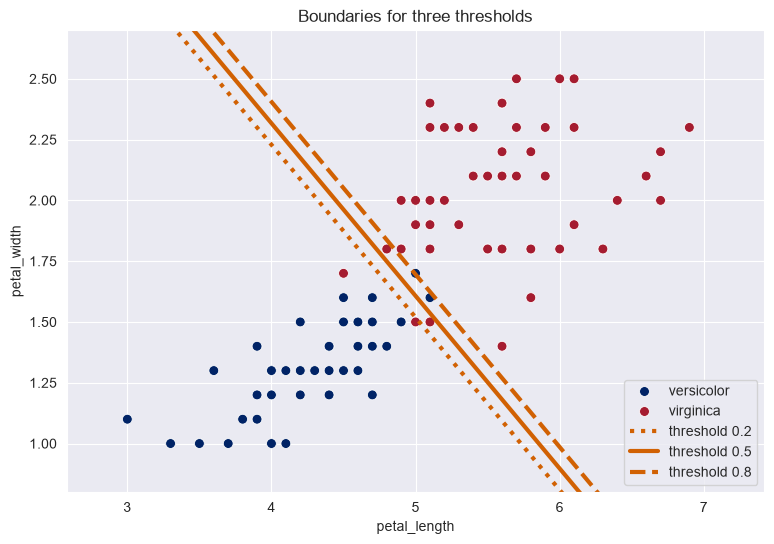

In [27]:
fig, ax = plt.subplots(figsize=(9, 6))

sns.scatterplot(
    data=two_species_df, 
    x='petal_length', 
    y='petal_width', 
    hue='species', 
    palette=SPECIES_PALETTE, 
    s=50, 
    ax=ax, 
)
for threshold, line_style in [(0.2, ':'), (0.5, '-'), (0.8, '--')]:
    ax.plot(
        length_grid, 
        boundary_width(length_grid, petal_lgr, threshold), 
        color=SAFFRON, 
        linewidth=3, 
        linestyle=line_style, 
        label=f'threshold {threshold}', 
    )
ax.set_ylim(0.8, 2.7)
ax.legend(loc='lower right')
ax.set_title('Boundaries for three thresholds')
plt.show()

# Summary

- **Train / test split**, as in every supervised model: the line is learned
  from the training flowers and checked on test flowers it has never seen.
- With two predictors, logistic regression splits the plane with a **straight
  line**: the decision boundary.
- The line is where P = 0.5, i.e. log-odds = 0, so it comes straight from
  `intercept_` and `coef_`: a classic line y = mx + b, with slope
  m = −β1/β2 and intercept b = −β0/β2. The line's b is not `intercept_`.
- `DecisionBoundaryDisplay` shades the probabilities; the computed line sits
  exactly on their 0.5 edge.
- **Separable classes** (setosa vs. the rest): many lines work, and the
  unregularized fit runs off toward infinite coefficients. Regularization
  keeps it finite.
- **Overlapping classes** (versicolor vs. virginica): the line has to choose,
  and a few flowers end up on the wrong side.
- A different threshold gives a **parallel line**.
- One predictor gives a boundary *point* (in the Default vignette, the balance
  where the S-curve crosses 0.5); three predictors give a *plane*.